[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zakariae-lazraq/ai-agents-healthcare-labs/blob/main/notebooks/Lab04_Image_Triage.ipynb)

# Lab 4 — Image triage with a human review queue
**AI Agents for Healthcare and Diagnostics** · Module 3 · about 60 minutes

**The situation.** Northbridge's digital pathology group receives thousands of H&E colorectal tissue tiles.
A classifier could sort the obvious ones automatically and send the uncertain ones to a pathologist. But
*where* to draw the line between "automatic" and "human" is a decision with consequences — and a classifier is
always confident about something, even a fake or a blank image.

**At the end of this lab you will be able to:**
- wrap an image classifier as an agent tool and route uncertain cases to a human queue;
- measure the trade-off between automation and safety, and choose a threshold you can defend;
- get a second opinion from Gemini's vision, and test the classifier with an AI-generated image;
- explain why "confident" does not mean "correct".

| Word | Meaning here |
|---|---|
| **Confidence** | the classifier's probability for its top class (0–1); not the probability of being right |
| **Threshold** | the minimum confidence for automatic sorting; below it, a human reviews |
| **Margin** | how far the top class is ahead of the runner-up; a close call goes to a human |
| **Review queue** | the list of tiles a pathologist must look at, each with a reason |

*Data: PathMNIST (MedMNIST v3, CC BY 4.0), derived from NCT-CRC-HE-100K — real H&E tiles, 9 tissue classes.*

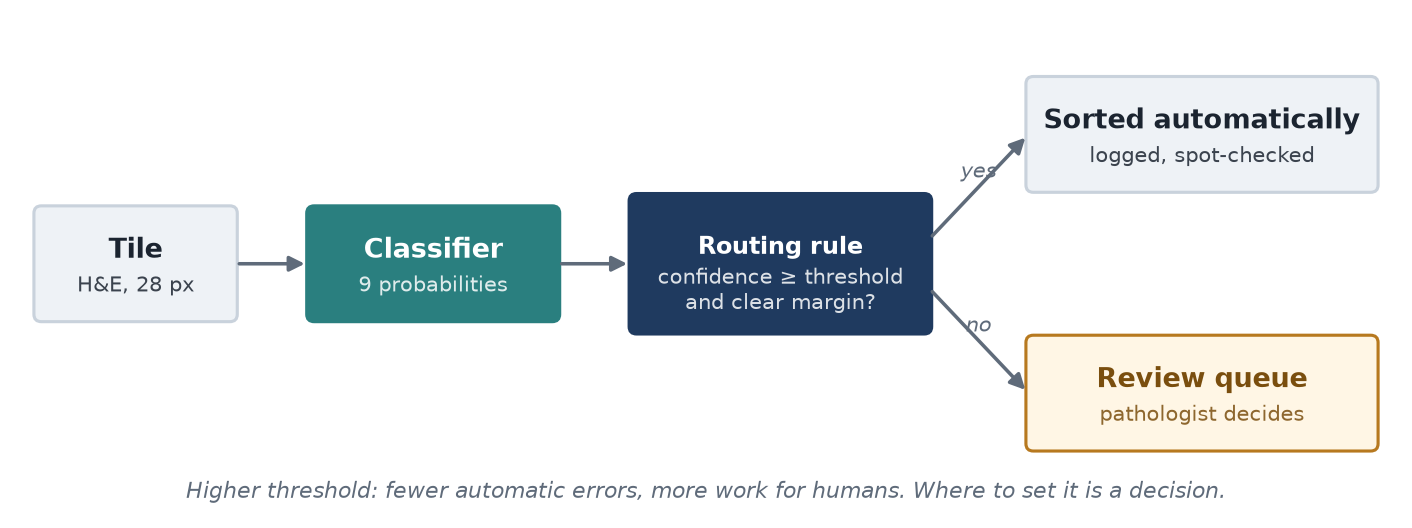

*The classifier scores; a rule in code routes; the pathologist decides on the queue.*

### Setup — run this cell (about 1 minute)
Same as in Lab 0: it installs the course tools, downloads the course files and checks your key. The code is folded: just run it.

In [ ]:
# @title Setup — click run and wait about 1 minute
import os, subprocess, sys
REPO = "https://github.com/zakariae-lazraq/ai-agents-healthcare-labs"
MODEL = "gemini-3.5-flash-lite"  # @param {type:"string"}
___ = "___"  # the blank you will replace in YOUR CELL

def _step(what, cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(f"FAILED: {what}. Run this cell again; if it fails twice, send the text below to the trainer:")
        print((r.stderr or r.stdout)[-800:])
        return False
    print(f"done: {what}")
    return True

try:
    import google.colab  # noqa: F401  — present only inside Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

_ready = True
if IN_COLAB:
    if not os.path.exists("/content/course"):
        _ready = _step("download course files", ["git", "clone", "-q", "--depth", "1", REPO, "/content/course"])
    if _ready:
        _ready = _step("install Google ADK", [sys.executable, "-m", "pip", "install", "-q", "google-adk==2.15.0"])
    sys.path.insert(0, "/content/course")

SETUP_OK, SETUP_RESULTS = False, []
if _ready:
    from google.adk.agents import Agent
    from labkit.setup import check_environment, show_checks
    from labkit.agents import make_model, run, DETERMINISTIC
    from labkit.ui import check, has_blank, ready, copy_box, done_card
    import numpy as np
    import matplotlib.pyplot as plt
    from IPython.display import HTML, display
    from labkit import DATA_DIR
    from labkit import triage
    from labkit.audit import AuditLog
    from labkit.ui import error_line
    LAB = DATA_DIR / "lab04"
    TRI = triage.load(LAB)          # 200 test tiles + the trained classifier
    QUEUE = []                      # the pathologist's review queue
    LOG = AuditLog()
    SETUP_RESULTS = check_environment(MODEL, ping_pubmed=False)
    SETUP_OK = show_checks(SETUP_RESULTS)

**What you should see:** every line marked **OK**, then *"Everything is ready"*. Same Setup as Lab 0.

**If it does not work**

| You see | Do this |
|---|---|
| FIX — API key found | Open Secrets (key icon, left sidebar): `GOOGLE_API_KEY`, *Notebook access* on; run Setup again |
| FIX — API key works, "busy" or "quota" | Wait 30–60 seconds, run Setup again |
| FAILED: download / install | Run Setup again; if it fails twice, send the text to the trainer |
| `NameError: ... is not defined` in later cells | Session restarted: click the cell, then **Runtime → Run before** |

## Part 1 — The tiles and the classifier (about 15 minutes)
Two tiles of each tissue class (enlarged ×4), then the classifier's card.

In [ ]:
# @title Look at the tiles and the model card — run this cell
display(HTML(triage.gallery_html(TRI, per_class=2)))
_c = TRI.card
print(f"{_c['name']} — {_c['architecture']}")
print(f"Accuracy: {_c['accuracy_validation']:.1%} on validation tiles (same slides as training), "
      f"{_c['accuracy_test']:.1%} on test tiles (different slides).")
print("The gap is a distribution shift: different patients and slides (same centre). A new laboratory, stain or "
      "scanner would usually lower accuracy further — see the colour-shifted tile in Task 4.")
for _l in _c["limits"]:
    print(" -", _l)

### Task 1 — Write the routing rule
<sub>IN THE NOTEBOOK · ABOUT 6 MIN</sub>

**Your task.** Decide in code which tiles may be sorted automatically and which must go to a pathologist.

**Steps**

1. `THRESHOLD`: the minimum top-class probability for automatic sorting — start with **0.80**.
2. `MARGIN`: how far the top class must be ahead of the runner-up — e.g. **0.20** (a 0.55 vs 0.40 call is too close).
3. Run your cell and the CHECK: it tests your rule on three cases.

In [ ]:
# YOUR CELL — replace every ___ , then run this cell
THRESHOLD = ___
MARGIN = ___

def route(top_p, second_p):
    """'auto' only if the top class is confident enough AND clearly ahead of the runner-up."""
    if top_p >= THRESHOLD and (top_p - second_p) >= MARGIN:
        return "auto"
    return "review"

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
try:
    _cases = [route(0.97, 0.02), route(0.65, 0.20), route(0.85, 0.80)]
    _err = ""
except Exception as _e:
    _cases, _err = ["?"] * 3, f"Your rule raised an error: {_e}"
_ok = check([
    (isinstance(THRESHOLD, (int, float)) and 0.5 <= THRESHOLD <= 0.99, "THRESHOLD between 0.50 and 0.99",
     _err or "Set THRESHOLD = 0.80 to start."),
    (_cases[0] == "auto", "Clear, confident tile (0.97 vs 0.02) → auto", _err or "Check the condition."),
    (_cases[1] == "review", "Unsure tile (0.65) → review", _err or "Tiles below THRESHOLD must go to review."),
    (_cases[2] == "review", "Close call (0.85 vs 0.80) → review",
     _err or "Set MARGIN, e.g. 0.20: a close call must go to review."),
])

<details><summary><b>Hint</b> — open only if you are stuck</summary>

`THRESHOLD = 0.80` and `MARGIN = 0.20`. The rule is code, not a prompt: it behaves the same every time.

</details>

### The trade-off: move the threshold
Pure code, no AI: your rule applied to all 200 tiles, for every threshold from 0.50 to 0.99. Green: accuracy of
the tiles sorted automatically. Amber: share sent to humans. Move the slider and read the table.

In [ ]:
# @title Threshold explorer — move the slider, then run
show_threshold = 0.80  # @param {type:"slider", min:0.5, max:0.99, step:0.01}
if not isinstance(globals().get("MARGIN"), (int, float)):
    raise SystemExit("Finish Task 1 first (THRESHOLD and MARGIN), then run this cell.")
def _rule(top_p, second_p, threshold):
    return "auto" if top_p >= threshold and (top_p - second_p) >= MARGIN else "review"
_grid = [round(0.50 + 0.01 * k, 2) for k in range(50)]
SWEEP = triage.sweep(TRI, _grid, route=_rule)
triage.sweep_chart(SWEEP, mark=show_threshold)
plt.show()
for _r in triage.sweep(TRI, [0.60, 0.80, 0.95, show_threshold], route=_rule):
    print(f"threshold {_r['threshold']:.2f}: {_r['to_humans_pct']:5.1f} % to humans · automatic accuracy "
          f"{_r['auto_accuracy_pct']} % · {_r['auto_errors']} wrong tiles sorted automatically "
          f"(tumour called non-tumour: {_r['tumour_missed']})")

### Task 2 — Choose the threshold you would defend
<sub>IN THE NOTEBOOK · ABOUT 5 MIN</sub>

**Your task.** A CAP or ISO 15189 assessor asks: why this threshold? Choose one and justify it in one sentence.

**Steps**

1. Use the explorer above: how many wrong tiles are sorted automatically, and how much work goes to humans, at your threshold?
2. Set your threshold and write your justification in the form, then run it and the CHECK.

In [ ]:
# @title Your threshold and why
# YOUR CELL — fill in the form on the right, then run this cell
my_threshold = 0.9  # @param {type:"slider", min:0.5, max:0.99, step:0.01}
justification = ""  # @param {type:"string"}

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
if "_rule" not in globals():
    raise SystemExit("Run the threshold explorer cell above first.")
_r = triage.sweep(TRI, [my_threshold], route=_rule)[0]
_ok = check([(len(justification.strip()) >= 20, "Justification written",
              "Write one sentence: errors you accept, review workload, how errors are caught.")])
if _ok:
    MY_THRESHOLD = my_threshold
    print(f"Your choice {my_threshold:.2f}: {_r['to_humans_pct']} % to humans, {_r['auto_errors']} wrong tiles "
          f"sorted automatically out of 200. Post it in the chat with your sentence.")

<details><summary><b>Hint</b> — open only if you are stuck</summary>

There is no single right answer. A defensible answer names the errors you accept, the review workload, and how automatic errors are still caught (e.g. a random spot-check of automatic tiles).

</details>

## Part 2 — The triage agent (about 20 minutes)
The agent gets two tools: `triage_images` (classifier + **your** routing rule) and `add_to_review_queue`.
It never decides the route itself — your code does. Its job: run the triage, queue every uncertain tile with a
clear reason, and report. Every tool call is written to the audit log by a callback, as in Lab 2.

### Task 3 — Write the triage agent's instruction
<sub>IN THE NOTEBOOK · ABOUT 6 MIN</sub>

**Your task.** Tell the agent what to do with your routing decisions, and what it must never do.

**Steps**

1. Call `triage_images` once with all the ids it is given.
2. Call `add_to_review_queue` for **every** image routed to 'review', with a reason quoting the top class, its probability and the runner-up.
3. Never change a route, never give a diagnosis; the pathologist decides.
4. Finish with one last line: `AUTO: <number> · REVIEW: <number>`.
5. Run your cell and the CHECK; the next cell builds the agent and triages 16 tiles.

In [ ]:
# YOUR CELL — replace every ___ , then run this cell
TRIAGE_INSTRUCTION = """___"""

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
_i = TRIAGE_INSTRUCTION.lower()
_blank = has_blank(TRIAGE_INSTRUCTION)
_ok = check([(False, "Instruction written", _blank)]) if _blank else check([
    ("triage_images" in _i, "Calls triage_images", "Name the tool triage_images."),
    ("add_to_review_queue" in _i and "reason" in _i, "Queues every review image with a reason",
     "Ask it to call add_to_review_queue with a reason for every 'review' image."),
    ("diagnos" in _i, "No diagnosis", "Write: never give a diagnosis; the pathologist decides."),
    ("auto:" in _i and "review:" in _i, "Fixed last line (AUTO / REVIEW)", "End with: AUTO: <n> · REVIEW: <n>"),
])

<details><summary><b>Hint</b> — open only if you are stuck</summary>

Five short lines are enough. The agent's value here is consistency and clear reasons, not judgement: the judgement is in your routing rule and in the pathologist.

</details>

In [ ]:
# @title Build the agent and triage 16 tiles — run this cell
print(f"The agent uses YOUR Task 1 rule: THRESHOLD = None, MARGIN = None "
      "(not the Task 2 choice).")
if "route" not in globals() or has_blank(globals().get("TRIAGE_INSTRUCTION", "___")):
    display(error_line("Finish Task 1 (routing rule) and Task 3 (instruction) first."))
    triage_agent = None
else:
    QUEUE.clear()
    _tools = triage.make_triage_tools(TRI, route, QUEUE)
    triage_images, add_to_review_queue = _tools["triage_images"], _tools["add_to_review_queue"]
    triage_agent = Agent(name="triage_agent", model=make_model(MODEL), instruction=TRIAGE_INSTRUCTION,
                         tools=[triage_images, add_to_review_queue], generate_content_config=DETERMINISTIC,
                         after_tool_callback=LOG.callback)
    _r = run(triage_agent, "Triage these images: IMG001, IMG002, IMG003, IMG004, IMG005, IMG006, IMG007, IMG008, IMG009, IMG010, IMG011, IMG012, IMG013, IMG014, IMG015, IMG016.")

In [ ]:
# @title The pathologist's review queue and the audit log — run this cell
_should = [i for i in ['IMG001', 'IMG002', 'IMG003', 'IMG004', 'IMG005', 'IMG006', 'IMG007', 'IMG008', 'IMG009', 'IMG010', 'IMG011', 'IMG012', 'IMG013', 'IMG014', 'IMG015', 'IMG016'] if route(*triage.top2(TRI.probs[TRI.index(i)])[1::2]) == "review"]
_queued = [q["image_id"] for q in QUEUE]
display(HTML(triage.queue_html(TRI, QUEUE)))
display(HTML(LOG.html()))
_ok = check([(sorted(_queued) == sorted(_should), f"Agent queued exactly the {len(_should)} tiles your rule sent to review",
              f"Your rule sent {_should} to review; the agent queued {_queued}. Re-run the cell above, or make "
              "the instruction say: for EVERY image routed to review.")])
if _ok:
    QUEUE_OK = True
_wrong = [i for i in ['IMG001', 'IMG002', 'IMG003', 'IMG004', 'IMG005', 'IMG006', 'IMG007', 'IMG008', 'IMG009', 'IMG010', 'IMG011', 'IMG012', 'IMG013', 'IMG014', 'IMG015', 'IMG016'] if i not in _should and TRI.probs[TRI.index(i)].argmax() != TRI.labels[TRI.index(i)]]
print(f"Teaching reveal: {len(_wrong)} of the tiles sorted automatically in this batch are WRONG "
      f"({', '.join(_wrong) or 'none'}). Confident is not correct — this is what spot-checks are for.")
_tm = [i for i in _wrong if TRI.labels[TRI.index(i)] == triage.TUMOUR]
if _tm:
    print(f"Clinically worst: {', '.join(_tm)} — adenocarcinoma sorted automatically as non-tumour (a missed tumour).")
print("Small batches vary: 16 tiles cannot show the 11 % average error rate precisely.")

### A second opinion from Gemini's vision
Gemini looks at the first tile in the queue (one API call). Compare it with the classifier and the true class.

In [ ]:
# @title Second opinion on the first queued tile — run this cell
if not QUEUE:
    print("The queue is empty: run the triage cell above first.")
else:
    _id = QUEUE[0]["image_id"]
    _i = TRI.index(_id)
    display(HTML(f"<img src='data:image/png;base64,{triage.png_b64(TRI.images[_i], scale=6)}' width='168'>"))
    print("Classifier:", triage.describe(TRI.probs[_i]))
    print("True class:", triage.CLASSES[int(TRI.labels[_i])])
    _so = triage.second_opinion(TRI, _id, MODEL)
    print("Gemini    :", _so["text"] or _so["message"])
    print("(A 28-pixel tile shown enlarged is close to the limit of what anyone can see; general vision models are "
          "not validated for histology — treat this as a discussion aid, not a reference.)")

### Task 4 — Fool the classifier with an AI-generated tile
<sub>IN THE GEMINI APP · ABOUT 8 MIN</sub>

**Your task.** See what a classifier does with an image that is not what it was trained on.

**Steps**

1. In the Gemini app, ask **Nano Banana**: *Generate a square microscopy image of H&E-stained colorectal adenocarcinoma tissue, close-up, no text.* Download the image. (Not available? Skip to step 3: the cell then uses prepared examples — a blank tile and a colour-shifted tile.)
2. Tick **use_my_image** and run the cell below to upload your image (leave it unticked to use the prepared examples). Note: PathMNIST tiles are about 112 µm wide at 0.5 µm/pixel; a generated image has another scale — the classifier cannot know.
3. Read the classifier's answer and its confidence, then record it in the form and run the CHECK.

In [ ]:
# @title Test images — tick use_my_image to upload your Nano Banana image; otherwise prepared examples are used
# YOUR CELL — fill in the form on the right, then run this cell
use_my_image = False  # @param {type:"boolean"}
_imgs = {}
if use_my_image and IN_COLAB:
    from google.colab import files
    try:
        for _name in files.upload():
            _imgs[_name] = triage.load_any_image(_name)
    except Exception as _e:
        print(f"Could not read your image ({_e}) — using the prepared examples instead.")
if not _imgs:
    _imgs = {"blank tile (prepared)": TRI.extra["blank"], "colour-shifted tile (prepared)": TRI.extra["colour_shifted"]}
for _name, _im in _imgs.items():
    _p = TRI.predict(_im[None])[0]
    display(HTML(f"<img src='data:image/png;base64,{triage.png_b64(_im, scale=4)}' width='112'>"))
    print(f"{_name}: {triage.describe(_p)} → route: {route(*triage.top2(_p)[1::2])}")
FAKE_TESTED = True
# Then record what happened (re-run this cell after choosing):
fake_result = "choose…"  # @param ["choose…", "Classified as the tissue I asked for — it cannot tell the image is fake", "Classified it with high confidence as something else (sent to auto)", "Low confidence (sent to review)", "Mixed"]

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
_ok = check([("FAKE_TESTED" in globals(), "Image tested", "Run the cell above first."),
             (globals().get("fake_result", "choose…") != "choose…", "Result recorded", "Choose what happened in the form.")])
if _ok:
    FAKE_RESULT = fake_result
    print("The classifier always answers with one of its 9 classes and probabilities summing to 1 — even for a "
          "fake or blank image. Confidence is not correctness: an input check is needed (challenge).")

<details><summary><b>Hint</b> — open only if you are stuck</summary>

A classifier has no 'none of the above'. A fake or blank tile can get a high confidence, and your routing rule would send it to automatic sorting. That is why images need a quality / scope check before classification. Detecting AI-generated images is hard in general; only Google-made images carry a SynthID watermark that Gemini can check — the classifier has no such ability.

</details>

## Discussion (8 minutes, with the group)
1. Which threshold would you defend to an assessor, and how would you catch the automatic errors that remain?
2. Gemini's second opinion and the classifier disagreed (or agreed): what would you do with a disagreement?
3. What should happen to an image the classifier was never trained for (fake, blank, another organ)?
4. Who is accountable for a tile sorted automatically that was wrong?

### Task 5 — Reject unusable images before classification
<sub>OPTIONAL CHALLENGE · ABOUT 10 MIN</sub>

**Your task.** For fast finishers. Write a quality check that rejects blank and blurred tiles before the classifier sees them.

**Steps**

1. Complete the two thresholds: a blank tile has almost no contrast (standard deviation of grey values below **1.0**); a blurred tile has little pixel-to-pixel change **relative to its contrast** (ratio below **0.3**). Why relative? Real 'background' tiles are smooth but low-contrast.
2. Run your cell and the CHECK: blank and blurred must be rejected, and at least 190 of the 200 real tiles accepted.

In [ ]:
# YOUR CELL — replace every ___ , then run this cell
def is_usable(image):
    """'' if the tile can be classified, otherwise the reason (blank or blurred)."""
    g = image.astype(float).mean(axis=2)
    if g.std() < ___:
        return "blank or nearly uniform image"
    sharpness = abs(np.diff(g, axis=0)).mean() + abs(np.diff(g, axis=1)).mean()
    if sharpness / g.std() < ___:
        return "image too blurred"
    return ""

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
try:
    _b, _bl = is_usable(TRI.extra["blank"]), is_usable(TRI.extra["blurred"])
    _real = sum(is_usable(_im) == "" for _im in TRI.images)
    _err = ""
except Exception as _e:
    _b = _bl = ""
    _real, _err = 0, f"Your check raised an error: {_e}"
_ok = check([(bool(_b), "Blank tile rejected", _err or "Use g.std() < 1.0."),
             (bool(_bl), "Blurred tile rejected", _err or "Use sharpness / g.std() < 0.3."),
             (_real >= 190, f"Real tiles accepted: {_real}/200", _err or "Thresholds too strict.")])
if _ok:
    QUALITY_DONE = True
    _cs = is_usable(TRI.extra["colour_shifted"])
    print("Colour-shifted tile:", repr(_cs) if _cs else "accepted — yet the classifier calls it 'debris' with "
          "probability 1.00. A quality check catches broken images, not images from another scanner or stain.")

<details><summary><b>Hint</b> — open only if you are stuck</summary>

`g.std() < 1.0` and `sharpness / g.std() < 0.3`. In production this check would run before triage_images, as a callback — like the guardrail in Lab 3.

</details>

## What you learned
1. **A classifier as a tool, routing in code:** the threshold and margin are your laboratory's decision.
2. **Automation is a trade-off you can measure:** fewer automatic errors cost more human review.
3. **Confidence is not correctness:** a classifier answers even for a fake or blank image.
4. **Traceability:** every routed tile and every queue entry is in the audit log, written by code.

## Finish — your status card
Type your name, run the cell, post a screenshot in the course chat.

In [ ]:
# @title Status card — type your name, run, then screenshot the card
participant_name = ""  # @param {type:"string"}
import datetime
_g = globals()
_lines = [f"Participant: {participant_name.strip() or 'NAME MISSING — type it in the box'}",
          f"Date: {datetime.date.today().isoformat()} · model {_g.get('MODEL', '?')}",
          f"{'OK ' if 'route' in _g else 'FIX'} — Routing rule written (Task 1)",
          f"{'OK ' if 'MY_THRESHOLD' in _g else 'FIX'} — Threshold chosen and justified: {_g.get('MY_THRESHOLD', '?')} (Task 2)",
          f"{'OK ' if 'QUEUE_OK' in _g else 'FIX'} — Agent queued exactly the review tiles (Task 3)",
          f"{'OK ' if 'FAKE_RESULT' in _g else 'FIX'} — Classifier tested on a fake/blank image (Task 4)",
          f"{'OK ' if 'QUALITY_DONE' in _g else 'n/a'} — Quality check (challenge)"]
done_card("Lab 4 — status", _lines, complete=bool(participant_name.strip()) and all(
    k in _g for k in ("route", "MY_THRESHOLD", "QUEUE_OK", "FAKE_RESULT")))

**Next: Lab 5 — FHIR agent.** Results leave the laboratory as structured messages: the agent drafts a valid FHIR
report, and code validates it.

*Course material for training only. PathMNIST © its authors, CC BY 4.0. Nothing here is a diagnosis.*